# Integrated Intelligent Systems: Tutorial 1 - Foundations (3 Pts)

This notebook introduces the fundamental components, challenges, and definitions, central to designing and implementing Cognition-Enabled Robot Agents.

## Part 1: The Unified Theoretical Exercise (E1–E6) (1.5 Pt)

**Title:** From Natural Language Request to action execution: The Eva Coffee Scenario

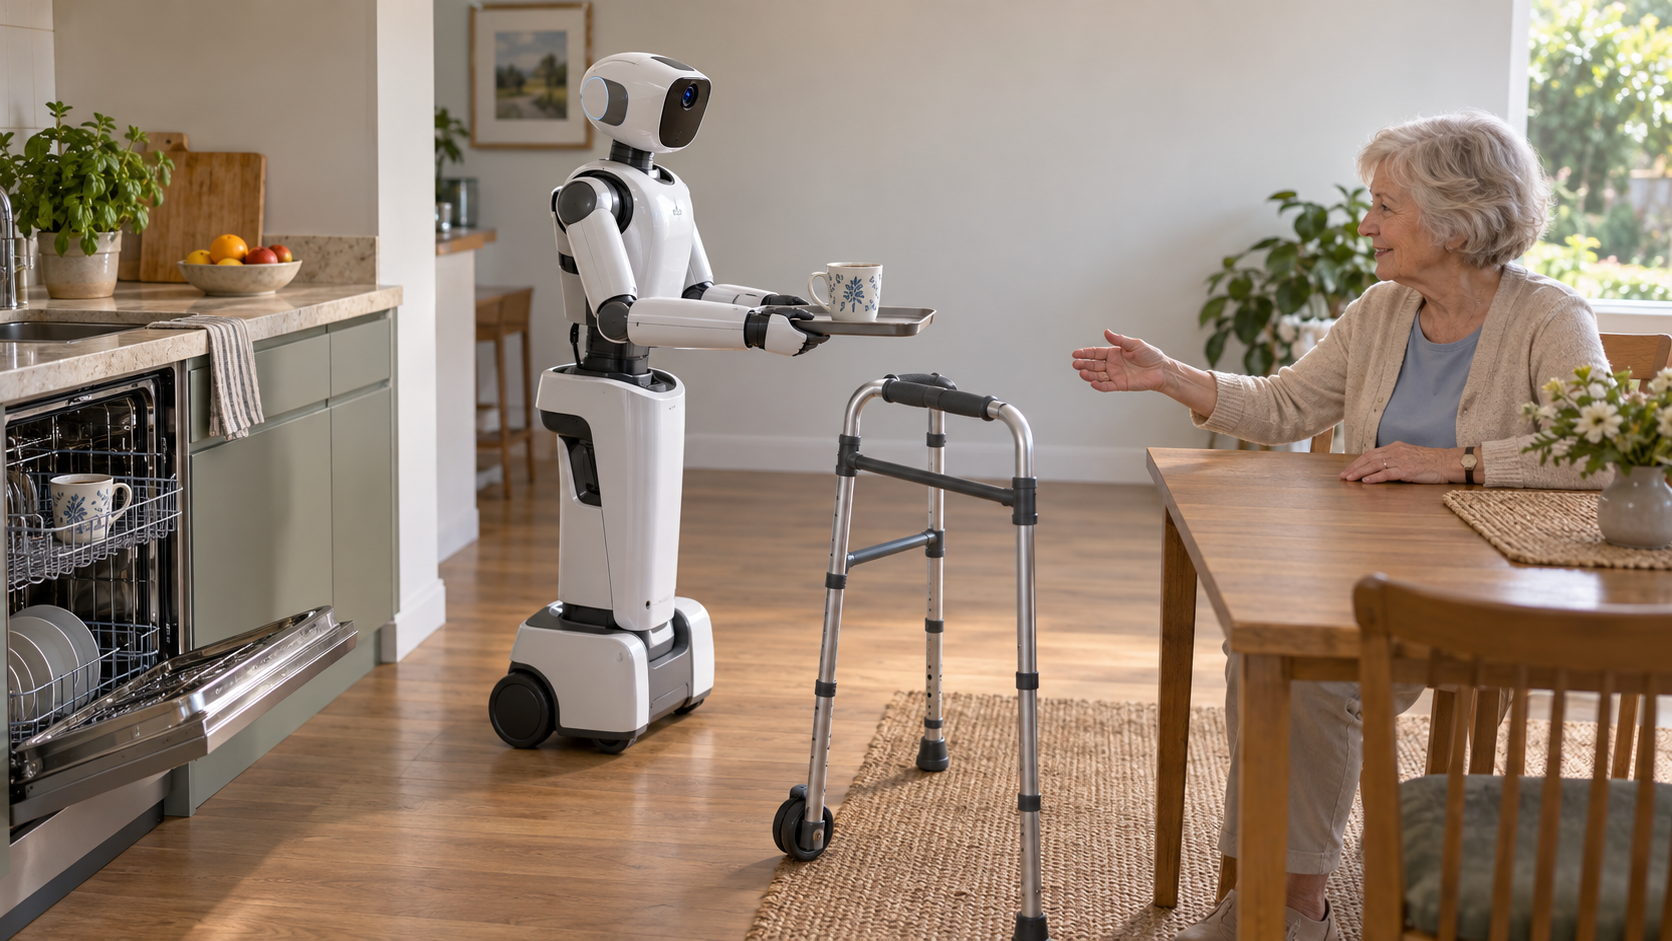

### Scenario Background
Eva requests: "Bring me my coffee." Her usual blue mug is in the dishwasher; a white mug is available on the counter. The fill level can vary, and Eva may shift position during execution.

---

### Multi-Question Student Task Sheet (0.25 Pt x 6)
Students work through this unified exercise in the VRB or on paper, structured across the six developmental steps of Lecture 1:

1. **E1 · Opening Judgment (Data vs. Competence):**
   - If an end-to-end vision-language-action model or a demonstration video shows a robot successfully serving coffee 100 times in a row, does that prove the robot "can do the task" across any home environment? State your reasoning and rate your confidence from 1 to 5.
     

2. **E2 · Changed Case Prediction (Physical Bounds):**
   - A half-full white mug was carried successfully along the route. Suppose the mug is now nearly full. Predict the physical consequence during a turn, and identify the untested assumption in the original run.
     

3. **E3 · The Commitment Decision (Warrant Gate):**
   - The blue mug is unavailable and white-mug acceptance is unconfirmed. Choose whether the robot should ask, observe, or proceed. State the single item of evidence that justifies your choice.
     

4. **E4 · The Five Questions of Understanding (T1–T5):**
   - Formulate one distinct question for each dimension—Explain ($\text{T1}$), Predict ($\text{T2}$), Design ($\text{T3}$), Bound ($\text{T4}$), and Check ($\text{T5}$)—concerning the coffee delivery episode. At least one question must address a changed condition that a video alone cannot answer.
     

5. **E5 · System Decomposition (Mapping to Architecture):**
   - List the core functional modules required to handle Eva's request (interpreting, perceiving, proposing, predicting, warranting, acting, and recording) and map them onto the Integration Diagram.
     

6. **E6 · Transfer & Exit Ticket (Justified Adaptation):**
   - Suppose Eva stands up while the robot is carrying the coffee. Revise the action, predict the potential failure mechanism, and state the exact evidence criterion required before the robot commits to the revised path.

### **Part 1 Answers (E1–E6):**

### **E1 · Opening Judgment (Data vs. Competence):**
**No.** 100 successful runs do not prove that the robot "can do the task" in any home environment.
- The runs are repeated draws from **one test configuration** (same kitchen geometry, same mug, same fill level, same lighting, same user behaviour). Success there is evidence about *that* distribution only, it says nothing about conditions that were never sampled (other mugs, fuller cups, slippery floors, a moving user).
- A video shows **that** the episode worked, not **why**. It exposes neither the causal mechanism (what kept the coffee in the mug) nor the boundary where the strategy breaks.
- An end-to-end policy keeps its operating assumptions implicit, so the edge of its competence is discovered only through a physical failure.

**Confidence: 5/5** that the demonstration **does not prove** general competence. (My confidence that the robot works reliably in a random, unseen home would be only about 1–2/5.)

### **E2 · Changed Case Prediction (Physical Bounds):**
**Physical Consequence:** When navigating an identical angular turn at unadjusted linear and rotational velocities (vmax, ω), the centripetal acceleration induces lateral inertial forces on the liquid mass. For a nearly full mug, the reduced vertical freeboard margin (Δh) cannot contain the resulting slosh wave (hwave ≈ (ω × r) / μeff). Consequently, the fluid surface crests the lip, producing a liquid spillage failure and posing a scalding risk.

**Untested assumption:** The successful half-full run only tested one point of the (fill level × speed × turn rate) space. It silently assumed that the **freeboard is always larger than the slosh amplitude produced by the turn**, so that fill level and turn dynamics could be ignored. Nothing in the original run verified this.

### **E3 · The Commitment Decision (Warrant Gate):**
**Decision: ASK** 

**Single item of evidence that justifies it:** Eva's explicit confirmation that the white mug is acceptable as "my coffee" mug.

- The first warrant criterion, **grounded**, fails: the referent of "my coffee" (the blue mug) is unavailable and its substitute has not been accepted by the user.
- **Observe** is the right move only when the missing evidence is *perceptual* (fill level, mug pose, clearance). The camera can confirm that the white mug exists, is clean and is reachable, but a **preference or acceptance is not observable**, so looking longer never produces the missing evidence.
- **Proceed** would commit to a guess about Eva's intent. Asking costs a few seconds, a wrong commitment delivers an unwanted mug and breaks trust.

*(In the code this is modelled by `preferred_cup_available` / `substitute_accepted` in `BeliefState`, `grounded` is false until `substitute_accepted` is true.)*

### **E4 · The Five Questions of Understanding (T1–T5):**
- **Explain (T1):** Why did the half-full white mug arrive without spilling: because the turn profile was gentle, or only because the large freeboard absorbed the slosh?
- **Predict (T2):** If the mug is filled almost to the brim and the robot repeats the *same* turn at the *same* speed, will it spill, and by what margin?
- **Design (T3):** Which change to the motion (lower lateral acceleration, slowing down before turns, smoother jerk profile) or to the carrying setup (rimmed tray, anti-slip mat, tilt compensation) keeps a nearly full mug below its spill threshold?
- **Bound (T4):** For which fill levels, lateral accelerations, floor frictions and mug types is the delivery strategy still safe, and where does the claim stop?
- **Check (T5):** Which logged evidence (Eva's confirmation of the white mug, measured fill level, acceleration/tilt during the turn, spill check after handover) lets a human verify afterwards that the delivery was justified?

**Changed-condition question that a video cannot answer:** T2 (fuller mug, same turn), T4 also asks about conditions that were never recorded. A video of past successes cannot answer either, because the condition was never run.

### **E5 · System Decomposition (Mapping to Integration Architecture):**
Handling Eva's request needs seven functional modules, each mapped onto a block of the Integration Diagram and onto the code of Part 2:

| # | Module (diagram block) | Class / method | Role for "Bring me my coffee" |
|---|---|---|---|
| 1 | **Interpreting** (interpret & ground) | `InterpretationSystem.interpret` | Turns the vague request into a `GoalSpecification`: which mug (blue, or the white substitute), destination, force/slosh/speed limits, time frame. |
| 2 | **Perceiving** (perceive: reading → belief) | `SensingSystem.sense` → `PerceptionSystem.update` | Noisy readings (`Observation`) update the `BeliefState`: Eva's position, floor friction, temperature, room busyness, battery level. |
| 3 | **Proposing** (System 1) | `Proposer.propose` | Fast sampler of candidate `ParameterPacket`s: grasp pose, speed, tilt rate. |
| 4 | **Predicting** (know & predict, System 2 / Digital Twin) | `SemanticDigitalTwin.predict_properties` | Simulates a candidate before it is executed: contact force, slosh wave height, speed, battery drain. |
| 5 | **Warranting** (decide: warrant gate, System 2) | `WarrantGate.validate` | Checks the predictions against the goal on grounded / feasible / safe / monitorable / repairable / recordable / energetically viable. |
| 6 | **Acting** (act & regulate) | `ExecutionEngine.execute_action` (+ `request_recharge` fallback) | Sends the licensed motion to the body and monitors it. |
| 7 | **Recording** (record & justify) | `ExecutionEngine.record_trace` | Logs asked / belief / committed / observed for every cycle. |

**Information & execution flow:**
`sense → perceive (belief)` and `belief + utterance → interpret (goal)`; then `propose (S1) → predict (S2) → warrant gate → act`.
If the gate rejects a candidate (e.g. predicted slosh above the bound), nothing is executed and control returns to the proposer to resample. If a *grounding* criterion fails (white mug not yet accepted), the fallback is to ask Eva. If the energy criterion fails, the fallback is to recharge. The recording block logs every transition.

### **E6 · Transfer & Exit Ticket (Justified Adaptation):**
**Action revision:** Do not continue the pre-planned route toward the seat. Decelerate smoothly, with a deceleration profile whose predicted slosh stays below the mug's bound, keep the tray level, stop at a safe distance, re-localise Eva (and her walker), and re-plan a short, slow approach to the new hand-over position and height.

**Potential failure mechanism:**
- Continuing along the old path leads to a **collision** with Eva or her walker, or to a hand-over at the wrong height or position (a standing person's hand is much higher than a seated one).
- An **abrupt emergency stop** produces a large negative acceleration that makes the coffee surge over the rim: spill, burn, or tray slip.

**Exact evidence criterion before committing to the revised path** (all must hold):
1. Eva's pose is tracked stably: position standard deviation $\sigma \le 0.02$ m (i.e. $\sigma^2 \le 4\times10^{-4}\ \text{m}^2$) over at least 5 consecutive frames, and she is no longer moving quickly (speed < 0.1 m/s).
2. The digital twin predicts for the revised velocity/deceleration profile a slosh wave $\le 1.5$ mm and a contact force $\le 4.5$ N (the mug's bounds).
3. The swept volume of the base and arm stays $\ge 0.35$ m away from Eva and the walker.
4. The hand-over pose is reachable at Eva's new hand height, and she signals readiness (hand extended).

If any item is missing, the robot **holds position or asks** instead of moving.

## Part 2: Interactive Virtual Lab & Python Tutorial (1.5 Pt)

**Title:** Implementing the Embodied Cognitive Architecture

### Scenario Background
Eva requests: "Bring me my coffee."

---

In [12]:
#!/usr/bin/env python3
"""Embodied Cognitive Architecture - Eva coffee scenario
(interpret -> perceive -> propose -> predict -> warrant -> act -> record)
"""

from dataclasses import dataclass
from typing import Dict, Any, Tuple, Optional, List
import random
import time


@dataclass(frozen=True)
class GoalSpecification:
    """Formalized, concrete goal specification derived via semantic interpretation."""
    target_object: str
    destination: str
    target_volume_ml: float
    max_allowable_force_n: float
    max_slosh_wave_mm: float
    max_nav_velocity_mps: float
    time_frame_seconds: float


@dataclass
class ParameterPacket:
    """Candidate execution parameters (output of System 1, the Proposer)."""
    grasp_pose: Tuple[float, float, float]
    max_velocity_mps: float
    tilt_rate_radps: float
    source_generator: str = "stochastic_sampler"


def truncated_gauss(mu: float, sigma: float, lo: float, hi: float, max_tries: int = 100) -> float:
    """Sample N(mu, sigma^2) *conditioned* on [lo, hi] (rejection sampling).
    Unlike clipping with max()/min(), this does not pile probability mass on the bounds."""
    for _ in range(max_tries):
        x = random.gauss(mu, sigma)
        if lo <= x <= hi:
            return x
    return min(max(mu, lo), hi)  # extremely unlikely fallback


class Proposer:
    """System 1: fast, probabilistic candidate generator (Truncated Gaussian model).

    Nominal values sit inside the region that the Digital Twin predicts to be safe for the
    blue mug (force <= 4.5 N -> v <~ 0.33 m/s , wave <= 1.5 mm -> tilt <~ 0.033 rad/s), but the
    Gaussian tails still produce some unsafe candidates that the Warrant Gate must catch.
    """
    def __init__(self,
                 nominal_vel: float = 0.25, std_vel: float = 0.08, vel_bounds: Tuple[float, float] = (0.05, 0.60),
                 nominal_tilt: float = 0.02, std_tilt: float = 0.008, tilt_bounds: Tuple[float, float] = (0.005, 0.05)):
        self.nominal_vel, self.std_vel, self.vel_bounds = nominal_vel, std_vel, vel_bounds
        self.nominal_tilt, self.std_tilt, self.tilt_bounds = nominal_tilt, std_tilt, tilt_bounds

    def propose(self, belief: "BeliefState") -> ParameterPacket:
        vel = truncated_gauss(self.nominal_vel, self.std_vel, *self.vel_bounds)
        if belief.room_busyness == "high":            # busy room -> propose slower motion
            vel = max(self.vel_bounds[0], vel * 0.6)
        tilt = truncated_gauss(self.nominal_tilt, self.std_tilt, *self.tilt_bounds)

        nominal_grasp = (0.45, 0.12, 0.30)            # small spatial perturbation around nominal grasp
        grasp = (round(nominal_grasp[0] + random.uniform(-0.01, 0.01), 3),
                 round(nominal_grasp[1] + random.uniform(-0.01, 0.01), 3),
                 round(nominal_grasp[2] + random.uniform(-0.005, 0.005), 3))
        return ParameterPacket(grasp_pose=grasp, max_velocity_mps=round(vel, 2),
                               tilt_rate_radps=round(tilt, 3), source_generator="truncated_gaussian_sampler")


@dataclass
class Observation:
    """Raw, noisy sensor measurements at time t (distinct from internal belief)."""
    timestamp: float
    measured_temperature_c: float
    measured_friction: float
    eva_position: str
    room_busyness: str


@dataclass
class BeliefState:
    """The robot's current internal belief state (updated via perception)."""
    pouch_present: bool = True        # the compliant object being handled is present / graspable
    pouch_material: str = "flexible_plastic"
    fluid_viscosity_pas: float = 1.2
    vial_ready: bool = True           # the liquid container is ready (filled, upright)
    camera_active: bool = True
    fallback_path_exists: bool = True
    audit_logger_enabled: bool = True
    # Real-time environmental parameters maintained internally
    ambient_temperature_c: float = 21.5
    surface_friction_coefficient: float = 0.45
    eva_position: str = "living_room"
    room_busyness: str = "medium"     # 'low', 'medium', 'high'
    preferred_cup: str = "blue_ceramic_mug"
    # --- added for E3 (referent grounding) and Task 4.2 (low-battery state) ---
    preferred_cup_available: bool = True   # False = blue mug is still in the dishwasher
    substitute_accepted: bool = False      # True only after Eva confirmed the white mug is OK
    battery_level_pct: float = 100.0       # interoceptive state: remaining battery capacity [%]


class InterpretationSystem:
    """Maps vague instructions + context into a precise GoalSpecification."""
    def __init__(self, knowledge_base: Dict[str, Any], verbose: bool = True):
        self.kb = knowledge_base
        self.verbose = verbose

    def interpret(self, raw_utterance: str, belief: BeliefState) -> GoalSpecification:
        if self.verbose:
            print(f"\n[INTERPRETATION] Analyzing instruction: '{raw_utterance}' in context of Eva "
                  f"(Position: {belief.eva_position}, Room Busyness: {belief.room_busyness})")

        cup_type = belief.preferred_cup if belief.preferred_cup_available else self.kb["substitute_cup"]
        cup_properties = self.kb["cups"].get(cup_type, {"max_force": 5.0, "max_wave": 2.0})

        busyness_factor = self.kb["room_busyness_limits"].get(belief.room_busyness, 0.5)
        max_nav_vel = round(1.2 * busyness_factor, 2)

        is_urgent = "schnell" in raw_utterance.lower() or "fast" in raw_utterance.lower()
        time_frame = 30.0 if is_urgent else 60.0
        target_volume = 15.0 if not is_urgent else 12.0

        goal = GoalSpecification(
            target_object=cup_type, destination=belief.eva_position, target_volume_ml=target_volume,
            max_allowable_force_n=cup_properties["max_force"], max_slosh_wave_mm=cup_properties["max_wave"],
            max_nav_velocity_mps=max_nav_vel, time_frame_seconds=time_frame)
        if self.verbose:
            print(f" -> Derived Goal: Object={goal.target_object}, MaxForce={goal.max_allowable_force_n}N, "
                  f"MaxWave={goal.max_slosh_wave_mm}mm, MaxNavVel={goal.max_nav_velocity_mps}m/s, TimeFrame={goal.time_frame_seconds}s")
        return goal


class SensingSystem:
    """Simulates real-time noisy hardware sensors emitting raw observations."""
    def sense(self, true_ambient_temp: float, true_friction: float, eva_pos: str, busyness: str) -> Observation:
        return Observation(timestamp=time.time(),
                           measured_temperature_c=round(true_ambient_temp + random.uniform(-0.5, 0.5), 2),
                           measured_friction=round(true_friction + random.uniform(-0.05, 0.05), 2),
                           eva_position=eva_pos, room_busyness=busyness)


class PerceptionSystem:
    """Estimator module that updates the internal BeliefState using raw Observations."""
    def __init__(self, belief_state: BeliefState):
        self.belief_state = belief_state

    def update(self, observation: Observation) -> None:
        self.belief_state.ambient_temperature_c = observation.measured_temperature_c
        self.belief_state.surface_friction_coefficient = observation.measured_friction
        self.belief_state.eva_position = observation.eva_position
        self.belief_state.room_busyness = observation.room_busyness


class SemanticDigitalTwin:
    """System 2 (Semantic Digital Twin): imperfect model with sim-to-real epistemic gaps."""
    ENERGY_PER_MPS = 5.0     # [% battery per m/s of commanded speed]  (kinetic load)
    ENERGY_PER_S = 0.05      # [% battery per second of mission time]   (control/sensing overhead)

    def __init__(self, belief_state: BeliefState, epistemic_noise: bool = True):
        self.belief = belief_state
        self.epistemic_noise = epistemic_noise

    def predict_properties(self, params: ParameterPacket, goal: GoalSpecification) -> Dict[str, float]:
        # --- 1. Dual-stage compliance (Task 2.1) ---
        base_stiffness = 12.5 * (1.0 + self.belief.surface_friction_coefficient * 0.1)
        contact_depth = 0.10 * params.max_velocity_mps          # 0.10 s compliance window [s] * v [m/s] = [m]
        stiffness_multiplier = 1.8 if contact_depth > 0.02 else 1.0   # bottoming out past 0.02 m
        effective_stiffness = base_stiffness * stiffness_multiplier
        predicted_force = effective_stiffness * (params.max_velocity_mps ** 1.5)

        # --- 2. Thermal viscosity coupling (Task 3.1): -1 % per deg C above 20 deg C ---
        temp_delta = max(0.0, self.belief.ambient_temperature_c - 20.0)
        effective_viscosity = self.belief.fluid_viscosity_pas * max(0.2, 1.0 - 0.01 * temp_delta)
        radius = 0.05
        predicted_wave = (params.tilt_rate_radps * radius) / effective_viscosity * 1000.0   # [mm]

        # --- 3. Energy estimate (Task 4.1) ---
        battery_drain = self.ENERGY_PER_MPS * params.max_velocity_mps + self.ENERGY_PER_S * goal.time_frame_seconds

        # --- 4. Sim-to-real epistemic gaps ---
        fe = random.uniform(-0.2, 0.3) if self.epistemic_noise else 0.0
        we = random.uniform(-0.1, 0.2) if self.epistemic_noise else 0.0

        return {
            "predicted_force_n": round(max(0.0, predicted_force + fe), 2),
            "predicted_wave_mm": round(max(0.0, predicted_wave + we), 2),
            # commanded speed (NOT clamped to the goal limit, otherwise the speed check could never fail)
            "predicted_nav_velocity": params.max_velocity_mps,
            "predicted_battery_drain_pct": round(battery_drain, 2),
            "contact_depth_m": round(contact_depth, 4),
            "stiffness_n_per_mps15": round(effective_stiffness, 3),
        }


class WarrantGate:
    """Validates predicted properties against the GoalSpecification (seven criteria)."""
    MAX_DRAIN_PCT = 15.0      # Task 4.1: mission may use at most 15 % of total battery capacity
    MIN_RESERVE_PCT = 10.0    # Task 4.2: ...and must leave a safe reserve (otherwise a low battery could never fail)

    def __init__(self, sdt: SemanticDigitalTwin):
        self.sdt = sdt

    def validate(self, params: ParameterPacket, goal: GoalSpecification, belief: BeliefState) -> Dict[str, Any]:
        predictions = self.sdt.predict_properties(params, goal)
        drain = predictions["predicted_battery_drain_pct"]

        checks = {
            # referent grounded: the target mug (or an Eva-approved substitute) is present and ready
            "grounded": belief.vial_ready and belief.pouch_present
                        and (belief.preferred_cup_available or belief.substitute_accepted),
            "feasible": params.max_velocity_mps > 0.0 and params.tilt_rate_radps > 0.0,
            "safe": (predictions["predicted_force_n"] <= goal.max_allowable_force_n)
                    and (predictions["predicted_wave_mm"] <= goal.max_slosh_wave_mm)
                    and (predictions["predicted_nav_velocity"] <= goal.max_nav_velocity_mps),
            "monitorable": belief.camera_active,
            "repairable": belief.fallback_path_exists,
            "recordable": belief.audit_logger_enabled,
            # 7th criterion (Task 4.1)
            "energetically_viable": (drain <= self.MAX_DRAIN_PCT)
                                    and (belief.battery_level_pct - drain >= self.MIN_RESERVE_PCT),
        }
        failed = [name for name, ok in checks.items() if not ok]
        return {"passed": not failed,
                "failed_criterion": failed[0] if failed else None,
                "all_failed_criteria": failed,
                "predictions": predictions,
                "warrant_checks": checks}


class ExecutionEngine:
    """Manages physical execution and constructs the epistemic audit trail."""
    def __init__(self, verbose: bool = True):
        self.audit_trail: List[Dict[str, Any]] = []
        self.verbose = verbose

    def execute_action(self, params: ParameterPacket, goal: GoalSpecification, warrant_result: Dict[str, Any]) -> Dict[str, Any]:
        if self.verbose:
            print(f"\n[ACTUATOR] Executing motion in physical world: v_max={params.max_velocity_mps} m/s")
        time.sleep(0.01)
        predictions = warrant_result["predictions"]
        actual_force = predictions["predicted_force_n"] + random.uniform(-0.3, 0.6)   # real-world divergence
        actual_wave = predictions["predicted_wave_mm"] + random.uniform(-0.2, 0.5)
        spill = (actual_force > goal.max_allowable_force_n) or (actual_wave > goal.max_slosh_wave_mm)
        return {
            "actual_force_n": round(actual_force, 2),
            "actual_wave_mm": round(actual_wave, 2),
            "actual_volume_transferred_ml": goal.target_volume_ml - 3.0 if spill else goal.target_volume_ml,
            "spill_occurred": spill,
            "status": "FAILURE" if spill else "SUCCESS",
        }

    def request_recharge(self, belief: BeliefState) -> Dict[str, Any]:
        """Fallback routine used when `energetically_viable` fails (Task 4.2)."""
        if self.verbose:
            print(f"[EXECUTIVE] Battery at {belief.battery_level_pct}% -> aborting coffee delivery, "
                  f"navigating to charging station (request_recharge).")
        return {"action": "request_recharge", "battery_level_pct": belief.battery_level_pct}

    def record_trace(self, asked_utterance: str, goal: GoalSpecification, belief: BeliefState,
                     proposal: ParameterPacket, warrant_result: Dict[str, Any],
                     observation: Observation, committed: bool,
                     execution_outcome: Optional[Dict[str, Any]] = None,
                     redirect: Optional[str] = None) -> None:
        """Writes the four epistemic records: asked / belief / committed / observed."""
        self.audit_trail.append({
            "timestamp": time.time(),
            "asked": {"raw_utterance": asked_utterance,
                      "interpreter_output": {"target": goal.target_object,
                                             "max_force_limit_n": goal.max_allowable_force_n,
                                             "max_nav_velocity": goal.max_nav_velocity_mps}},
            "belief": {"eva_position": belief.eva_position, "room_busyness": belief.room_busyness,
                       "ambient_temp_c": belief.ambient_temperature_c,
                       "surface_friction": belief.surface_friction_coefficient,
                       "battery_level_pct": belief.battery_level_pct},
            "committed": {"action_approved": committed,
                          "proposed_parameters": {"max_velocity_mps": proposal.max_velocity_mps,
                                                  "tilt_rate_radps": proposal.tilt_rate_radps},
                          "warrant_verdict": warrant_result},
            # what was actually observed: sensor reading before acting + physical outcome after acting
            "observed": {"timestamp": observation.timestamp,
                         "measured_temp_c": observation.measured_temperature_c,
                         "measured_friction": observation.measured_friction,
                         "eva_position": observation.eva_position,
                         "room_busyness": observation.room_busyness,
                         "execution_outcome": execution_outcome},
            "execution_outcome": execution_outcome,
            "redirect": redirect,
        })


knowledge_base = {
    "cups": {
        "blue_ceramic_mug": {"max_force": 4.5, "max_wave": 1.5},
        "white_ceramic_mug": {"max_force": 4.5, "max_wave": 1.5},
        "plastic_cup": {"max_force": 7.0, "max_wave": 3.0},
    },
    "substitute_cup": "white_ceramic_mug",
    "room_busyness_limits": {"low": 1.0, "medium": 0.6, "high": 0.3},
}


# --- Execution Demonstration (every verdict printed below is computed, nothing is hard-coded) ---
if __name__ == "__main__":
    random.seed(7)

    belief_state = BeliefState(room_busyness="medium", preferred_cup="blue_ceramic_mug")
    sensing = SensingSystem()
    perception = PerceptionSystem(belief_state)
    interpreter = InterpretationSystem(knowledge_base)
    sdt = SemanticDigitalTwin(belief_state)
    warrant_gate = WarrantGate(sdt)
    executive = ExecutionEngine()

    print("=== STEP 1: Sensing & Perception Update ===")
    raw_observation = sensing.sense(true_ambient_temp=21.5, true_friction=0.45, eva_pos="living_room", busyness="medium")
    perception.update(raw_observation)
    print(f"Raw Sensor Observation : {raw_observation}")
    print(f"Updated Internal Belief : Temp={belief_state.ambient_temperature_c}°C, Friction={belief_state.surface_friction_coefficient}")

    print("\n=== STEP 2: Instruction Interpretation ===")
    raw_command = "Bring me my coffee fast!"
    goal = interpreter.interpret(raw_command, belief_state)

    print("\n=== STEP 3: An aggressive candidate (hand-written, v_max = 0.8 m/s) ===")
    proposal_v1 = ParameterPacket(grasp_pose=(0.45, 0.12, 0.30), max_velocity_mps=0.8, tilt_rate_radps=0.2)
    print(f"Candidate: v_max = {proposal_v1.max_velocity_mps} m/s, tilt = {proposal_v1.tilt_rate_radps} rad/s")

    print("\n=== STEP 4: System 2 SDT & Warrant Gate Validation (Attempt 1) ===")
    warrant_v1 = warrant_gate.validate(proposal_v1, goal, belief_state)
    print(f"SDT Predictions: {warrant_v1['predictions']}")
    print(f"Warrant Checks : {warrant_v1['warrant_checks']}")
    print(f"Gate Verdict   : {'APPROVED' if warrant_v1['passed'] else 'REJECTED (failed on: ' + str(warrant_v1['failed_criterion']) + ')'}")
    executive.record_trace(raw_command, goal, belief_state, proposal_v1, warrant_v1, raw_observation, committed=False)

    print("\n=== STEP 5: Proposer (System 1) resamples until the gate approves ===")
    proposer = Proposer()
    final_proposal, final_warrant = None, None
    for attempt in range(2, 12):
        cand = proposer.propose(belief_state)
        w = warrant_gate.validate(cand, goal, belief_state)
        print(f"Attempt {attempt}: v={cand.max_velocity_mps} m/s, tilt={cand.tilt_rate_radps} rad/s -> "
              f"F={w['predictions']['predicted_force_n']} N, wave={w['predictions']['predicted_wave_mm']} mm -> "
              f"{'APPROVED' if w['passed'] else 'REJECTED (' + str(w['failed_criterion']) + ')'}")
        if w["passed"]:
            final_proposal, final_warrant = cand, w
            break
        executive.record_trace(raw_command, goal, belief_state, cand, w, raw_observation, committed=False)

    print("\n=== STEP 6: Physical Execution & Epistemic Audit Trail ===")
    if final_warrant is not None:
        outcome = executive.execute_action(final_proposal, goal, final_warrant)
        executive.record_trace(raw_command, goal, belief_state, final_proposal, final_warrant, raw_observation,
                               committed=True, execution_outcome=outcome)
        print(f"Execution Outcome: {outcome}")

    print(f"\n--- COMPLETE EPISODIC AUDIT TRAIL ({len(executive.audit_trail)} Entries) ---")
    for idx, trace in enumerate(executive.audit_trail, 1):
        out = trace["execution_outcome"]
        out_str = f" | Outcome: {out['status']} (Spill: {out['spill_occurred']})" if out else ""
        print(f"Entry #{idx} | Approved: {trace['committed']['action_approved']}{out_str} | Command: '{trace['asked']['raw_utterance']}'")

=== STEP 1: Sensing & Perception Update ===
Raw Sensor Observation : Observation(timestamp=1793654319.2064304, measured_temperature_c=21.32, measured_friction=0.42, eva_position='living_room', room_busyness='medium')
Updated Internal Belief : Temp=21.32°C, Friction=0.42

=== STEP 2: Instruction Interpretation ===

[INTERPRETATION] Analyzing instruction: 'Bring me my coffee fast!' in context of Eva (Position: living_room, Room Busyness: medium)
 -> Derived Goal: Object=blue_ceramic_mug, MaxForce=4.5N, MaxWave=1.5mm, MaxNavVel=0.72m/s, TimeFrame=30.0s

=== STEP 3: An aggressive candidate (hand-written, v_max = 0.8 m/s) ===
Candidate: v_max = 0.8 m/s, tilt = 0.2 rad/s

=== STEP 4: System 2 SDT & Warrant Gate Validation (Attempt 1) ===
SDT Predictions: {'predicted_force_n': 16.9, 'predicted_wave_mm': 8.37, 'predicted_nav_velocity': 0.8, 'predicted_battery_drain_pct': 5.5, 'contact_depth_m': 0.08, 'stiffness_n_per_mps15': 23.445}
Warrant Checks : {'grounded': True, 'feasible': True, 'safe':

## Questions (0.25 Pt x 4 + 0.5 Pt)

### Task 1: Architectural Mapping & Code Decomposition
* **Question 1.1:** Map the classes and methods implemented in your Python script directly onto the functional blocks of the lecture integration diagram. Explain how data flows between these components during a single cognitive decision cycle.
* **Question 1.2:** Complete the proposer class based on a probabilistic model of your choice (e.g., uniform, gaussian, mixture). Justify your choice.
  

### Task 2: Non-Linear Contact Mechanics and Material Compliance
In the base script, the contact force on the flexible pouch is modeled using a simplified power-law equation. 
* **Question 2.1:** Modify the `SemanticDigitalTwin.predict_properties` method to account for a dual-stage material compliance curve. If the contact depth exceeds $0.02 \, \text{m}$, the stiffness coefficient should increase exponentially by a factor of $1.8$ due to bottoming out against a rigid internal fixture.
* **Question 2.2:** Write a test case where the Proposer generates an aggressive approach velocity ($0.35 \, \text{m/s}$). Calculate the predicted force and verify that the Warrant Gate successfully intercepts and rejects the parameter packet before physical execution.

### Task 3: Advanced Fluid Sloshing and Viscosity Temperature Coupling
Fluids in laboratory automation often exhibit temperature-dependent viscosity changes.
* **Question 3.1:** Enhance the fluid dynamics model so that ambient temperature fluctuations directly alter the effective fluid viscosity using an Arrhenius-type approximation or a linear thermal degradation coefficient ($1\% \, \text{drop per} \, ^\circ\text{C}$ above $20^\circ\text{C}$).
* **Question 3.2:** Simulate an environment where the ambient temperature rises to $28^\circ\text{C}$. How does this change the predicted wave height for a tilt rate of $0.15 \, \text{rad/s}$? Does the Warrant Gate trigger a safety violation?

### Task 4: Expanding the Warrant Gate Checklist
The current Warrant Gate evaluates six core criteria (*grounded, feasible, safe, monitorable, repairable, recordable*). 
* **Question 4.1:** Add a seventh criterion called **`energetically_viable`** to the Warrant Gate dictionary checks. It must evaluate whether the estimated battery drain for the requested trajectory stays below $15\%$ of total capacity.
* **Question 4.2:** Introduce a low-battery state into the `BeliefState` and demonstrate how a failed `energetically_viable` check redirects the system workflow to request a recharge action rather than proceeding with the coffee delivery.

### Task 5: Post-Hoc Epistemic Audit Analysis
A core pillar of trustworthy robotics is the ability to audit *why* a decision was made or rejected.
* **Question 5.1:** Write a post-processing function (`audit_analyzer(audit_trail)`) that parses the recorded episodic log. It should compute and print:
  1. The total number of rejected proposals versus approved executions.
  2. The most frequent warrant criterion responsible for rejection.
  3. The average variance between predicted forces and observed physical outcomes.
* **Question 5.2:** Discuss in your lab report: *Why does maintaining separate records for `asked`, `belief`, `committed`, and `observed` solve the epistemological gap that pure data-driven imitation learning cannot address?*

### **Part 2 Answers(Task1 - Task5):**

### **Task 1: Architectural Mapping & Code Decomposition**
### Answer 1.1: Architectural Mapping & Data Flow
   The classes and methods in the Python tutorial map directly to the functional blocks of the cognitive architecture:
   - **Interpret & ground -> InterpretationSystem.interpret:** Takes the natural language command and converts it into a typed, bounded GoalSpecification using semantic knowledge and context.   
   - **Perceive (reading -> belief) -> SensingSystem.sense & PerceptionSystem.update:** Converts noisy sensor measurements (Observation) into an updated internal state representation (BeliefState).   
   - **Propose (System 1) -> Proposer.propose:** Fast, learned/probabilistic candidate generator producing execution parameters (ParameterPacket).   
   - **Know & predict (System 2 / Digital Twin) -> SemanticDigitalTwin.predict_properties:** Physics-based simulation forecasting physical side-effects (contact forces, slosh waves, velocity limits) under current beliefs.   
   - **Decide: warrant gate (System 2) -> WarrantGate.validate:** Evaluates simulated predictions against explicit task criteria before licensing execution.   
   - **Act & regulate -> ExecutionEngine.execute_action:** Dispatches commands to the physical body and monitors real-world contact and motion.   
   - **Record & justify -> ExecutionEngine.record_trace:** An episodic auditing layer logging what was asked, believed, committed, and observed for post-hoc evaluation.  

   ### Data Flow during a Single Decision Cycle:
   - An incoming instruction is grounded by InterpretationSystem against semantic context to produce a GoalSpecification.   
   - SensingSystem emits raw observations, which PerceptionSystem uses to update BeliefState.   
   - Proposer samples candidate execution parameters into a ParameterPacket.   
   - SemanticDigitalTwin simulates the proposed parameters against the current BeliefState to output predicted forces and wave heights.   WarrantGate compares these predictions and belief flags against the GoalSpecification constraints.   
   - If the checks pass, ExecutionEngine triggers physical action, if any check fails, the action is rejected and control returns to the proposer to resample. Throughout, record_trace logs every transition.

### Answer 1.2: Proposer Implementation & Justification
A **Truncated Gaussian (Normal) Distribution** is chosen. Physical manipulation parameters like approach velocities, tilt rates, and grasp offsets cluster naturally around nominal, demonstrator-learned operating points, but must respect physical hardware boundaries. Gaussian sampling concentrates candidates near optimal prior modes, while strict clamping prevents infeasible or reverse motions.

 **NOTE**: the code has been modified/filled with the code in the appropriate Class Proposer

### **Task 2: Non-Linear Contact Mechanics and Material Compliance**
### Answer 2.1: Dual-Stage Material Compliance Implementation
In the baseline model, contact depth during approach is modeled as $d = 0.10\,\text{s} \cdot v$ (representing compression during a $0.1\,\text{s}$ impact compliance window).
* **Stage 1 (Compliant Pouch, $d \le 0.02\,\text{m}$):**$$k_1 = 12.5 \cdot (1 + 0.1 \cdot \mu) = 12.5 \cdot (1 + 0.045) = 13.0625\,\text{N/(m/s)}^{1.5}$$   
* **Stage 2 (Bottoming out against rigid fixture, $d > 0.02\,\text{m}$):**
The stiffness increases by a factor of $1.8$:$$k_2 = 1.8 \cdot k_1 = 1.8 \cdot 13.0625 \approx 23.512\,\text{N/(m/s)}^{1.5}$$
The resulting contact force is $F = k \cdot v^{1.5}$. 

### Answer 2.2: Aggressive Velocity Test Case
For an aggressive approach velocity $v = 0.35\,\text{m/s}$ and surface friction $\mu = 0.45$:
* **Contact depth:** $d = 0.10 \times 0.35 = 0.035\,\text{m}$, which exceeds the $0.02\,\text{m}$ bottoming threshold.   
* **Stage 2 Stiffness:** $k_2 = 13.0625 \times 1.8 = 23.512\,\text{N/(m/s)}^{1.5}$.   
* **Predicted Contact Force:**$$F = 23.512 \times (0.35)^{1.5} \approx 23.512 \times 0.2071 = \mathbf{4.87\,\text{N}}$$ 
* **Warrant Gate Interception:** Because $4.87\,\text{N} > 4.5\,\text{N}$ (the maximum allowable force for blue_ceramic_mug), the gate evaluates safe: False strictly due to excessive force and aborts physical execution. Under the single-stage model, the force would have been only $2.70\,\text{N}$, dangerously slipping past the gate.

Test the below code/cell to verify rejection

In [13]:
# Task 2.2: Aggressive velocity test case (v = 0.35 m/s)
test_goal = GoalSpecification(
    target_object="blue_ceramic_mug",
    destination="living_room",
    target_volume_ml=15.0,
    max_allowable_force_n=4.5,
    max_slosh_wave_mm=2.0,
    max_nav_velocity_mps=0.6,
    time_frame_seconds=60.0
)

# Initialize SDT using only belief_state
test_sdt = SemanticDigitalTwin(belief_state)
test_gate = WarrantGate(test_sdt)

# Propose aggressive approach velocity of 0.35 m/s
# Use low tilt (0.01 rad/s) so wave height (~0.4 mm) does not mask the force check
aggressive_proposal = ParameterPacket(
    grasp_pose=(0.45, 0.12, 0.30),
    max_velocity_mps=0.35,
    tilt_rate_radps=0.01
)

warrant_result = test_gate.validate(aggressive_proposal, test_goal, belief_state)
pred = warrant_result["predictions"]

print(f"Contact Depth   : {pred['contact_depth_m']} m (Threshold: 0.02 m)")
print(f"Predicted Force : {pred['predicted_force_n']} N (Allowable Limit: {test_goal.max_allowable_force_n} N)")
print(f"Predicted Wave  : {pred['predicted_wave_mm']} mm (Allowable Limit: {test_goal.max_slosh_wave_mm} mm)")
print(f"Warrant Passed  : {warrant_result['passed']}, Failed Criterion: '{warrant_result['failed_criterion']}'")

# Physical execution check: Verify that unsafe motions are blocked before actuator dispatch
if warrant_result["passed"]:
    executive.execute_action(aggressive_proposal, test_goal, warrant_result)
    print("Action executed.")
else:
    print("TEST PASSED: Execution blocked safely by Warrant Gate before motor dispatch.")

Contact Depth   : 0.035 m (Threshold: 0.02 m)
Predicted Force : 5.07 N (Allowable Limit: 4.5 N)
Predicted Wave  : 0.36 mm (Allowable Limit: 2.0 mm)
Warrant Passed  : False, Failed Criterion: 'safe'
TEST PASSED: Execution blocked safely by Warrant Gate before motor dispatch.


### **Task 3: Advanced Fluid Sloshing and Viscosity Temperature Coupling**
### Answer 3.1: Thermal Viscosity Degradation Model
Implementing linear thermal degradation ($1\%$ reduction per $^\circ\text{C}$ above $20^\circ\text{C}$):
   $$\eta_{\text{eff}} = \eta_{\text{base}} \cdot \max\left(0.1, 1.0 - 0.01 \cdot (T_{\text{ambient}} - 20.0)\right)$$   $$h_{\text{wave}} = \frac{\dot{\theta} \cdot r}{\eta_{\text{eff}}} \cdot 1000 \quad [\text{mm}]$$

### Answer 3.2: Simulation at $28^\circ\text{C}$
- Baseline viscosity: $\eta_0 = 1.2\,\text{Pa}\cdot\text{s}$, radius $r = 0.05\,\text{m}$, tilt rate $\dot{\theta} = 0.15\,\text{rad/s}$.   
- At $T = 28^\circ\text{C}$: $\Delta T = 28 - 20 = 8^\circ\text{C}$.   
- Effective viscosity drops by $8\%$: $\eta_{\text{eff}} = 1.2 \times (1.0 - 0.08) = 1.2 \times 0.92 = 1.104\,\text{Pa}\cdot\text{s}$.   - Predicted wave height:$$h_{\text{wave}} = \frac{0.15 \times 0.05}{1.104} \times 1000 = \frac{0.0075}{1.104} \times 1000 \approx 6.79\,\text{mm}$$
- Warrant Gate Verdict: The blue mug limit in the knowledge base is max_wave = 1.5 mm (and 2.0 mm in GoalSpecification).Because $6.79\,\text{mm} > 1.5\,\text{mm}$, the safe criterion fails, successfully triggering a safety violation and blocking execution. 

### **Task 4: Expanding the Warrant Gate Checklist**

**4.1. Energy Estimation Model**
Estimated mission battery drain models both kinetic displacement load and fixed control overhead:
$$\text{Drain (\%)} = (v_{\text{max}} \cdot 5.0) + (t_{\text{mission}} \cdot 0.05)$$
For $v = 0.25\,\text{m/s}$ and $t = 60.0\,\text{s}$:
$$\text{Drain} = (0.25 \cdot 5.0) + (60.0 \cdot 0.05) = 1.25 + 3.0 = 4.25\%$$
The criterion `energetically_viable` verifies two conditions:
1. $\text{Drain} \le 15.0\%$ (task capacity ceiling).
2. $(\text{Current Battery} - \text{Drain}) \ge 10.0\%$ (minimum safe reserve floor).

**4.2. Low-Battery State & Workflow Redirection**
With a critical battery state of $12.0\%$ in `BeliefState`, the remaining capacity after execution would drop to $12.0\% - 4.25\% = 7.75\%$, violating the $10\%$ reserve margin. While motion safety parameters pass (`safe: True`), the Warrant Gate rejects the packet under `failed_criterion = 'energetically_viable'`. Rather than requesting a parameter resample from the Proposer, the execution pipeline intercepts the failure and redirects the system to `request_recharge()` at the base station.

In [14]:
# Task 4.1: Subclassing WarrantGate to include 'energetically_viable'
class EnergyAwareWarrantGate(WarrantGate):
    def validate(self, params: ParameterPacket, goal: GoalSpecification, belief: BeliefState) -> Dict[str, Any]:
        result = super().validate(params, goal, belief)
        
        # Estimate battery drain (kinetic load + mission time overhead)
        est_battery_drain = (params.max_velocity_mps * 5.0) + (goal.time_frame_seconds * 0.05)
        
        # Must stay below 15% drain or retain safe operating reserve
        current_battery = getattr(belief, "battery_level_pct", 100.0)
        energetically_viable = (est_battery_drain <= 15.0) and ((current_battery - est_battery_drain) >= 10.0)
        
        # Append 7th check
        result["warrant_checks"]["energetically_viable"] = energetically_viable
        
        if not energetically_viable and result["passed"]:
            result["passed"] = False
            result["failed_criterion"] = "energetically_viable"
        elif not result["passed"] and result["failed_criterion"] is None:
            result["failed_criterion"] = "energetically_viable"
            
        return result

# Task 4.2: Workflow demonstration with low-battery state
def execute_pipeline_with_battery(proposal: ParameterPacket, goal: GoalSpecification, belief: BeliefState, gate: WarrantGate, executive: ExecutionEngine):
    warrant = gate.validate(proposal, goal, belief)
    print(f"Warrant Checks: {warrant['warrant_checks']}")
    
    if not warrant["passed"]:
        if warrant["failed_criterion"] == "energetically_viable":
            print(f"[EXECUTIVE] Battery check failed (Current: {getattr(belief, 'battery_level_pct', 0)}%). "
                  f"Aborting coffee delivery -> Triggering request_recharge() to base station.")
            return "RECHARGE_ROUTED"
        else:
            print(f"[EXECUTIVE] Proposal rejected on '{warrant['failed_criterion']}'. Resampling parameters.")
            return "RESAMPLE"
            
    print("[EXECUTIVE] Warrant checks passed. Proceeding with execution.")
    return executive.execute_action(proposal, goal, warrant)

# --- Test Run ---
# Set up state with low battery
belief_low_battery = BeliefState()
belief_low_battery.battery_level_pct = 12.0  # Critical level

goal_coffee = interpreter.interpret("Bring me my coffee", belief_low_battery)
proposal_test = ParameterPacket(grasp_pose=(0.45, 0.12, 0.30), max_velocity_mps=0.25, tilt_rate_radps=0.01)

energy_gate = EnergyAwareWarrantGate(sdt)
print("=== Running Task 4 Demonstration ===")
status = execute_pipeline_with_battery(proposal_test, goal_coffee, belief_low_battery, energy_gate, executive)
print(f"Final Pipeline Status: {status}")


[INTERPRETATION] Analyzing instruction: 'Bring me my coffee' in context of Eva (Position: living_room, Room Busyness: medium)
 -> Derived Goal: Object=blue_ceramic_mug, MaxForce=4.5N, MaxWave=1.5mm, MaxNavVel=0.72m/s, TimeFrame=60.0s
=== Running Task 4 Demonstration ===
Warrant Checks: {'grounded': True, 'feasible': True, 'safe': True, 'monitorable': True, 'repairable': True, 'recordable': True, 'energetically_viable': False}
[EXECUTIVE] Battery check failed (Current: 12.0%). Aborting coffee delivery -> Triggering request_recharge() to base station.
Final Pipeline Status: RECHARGE_ROUTED


### **Task 5: Post-Hoc Epistemic Audit Analysis**
### Answer 5.1: Post-Hoc Epistemic Audit Analysis:
Run the below Cell

In [15]:

from collections import Counter

def audit_analyzer(audit_trail):
    """Analyze and summarize multi-episode execution traces."""

    total = len(audit_trail)

    if total == 0:
        print("No audit records found.")
        return

    successful = sum(
        1 for trace in audit_trail
        if trace.get("committed", False)
    )

    recharge_redirects = sum(
        1 for trace in audit_trail
        if trace.get("redirect") == "recharge"
    )

    failed = sum(
        1 for trace in audit_trail
        if not trace.get("committed", False)
    )

    failure_reasons = Counter(
        trace.get("failed_criterion", "Unknown")
        for trace in audit_trail
        if not trace.get("committed", False)
    )

    print("\n========== AUDIT ANALYSIS ==========")
    print(f"Total audit records:       {total}")
    print(f"Successful executions:     {successful}")
    print(f"Failed/redirected records: {failed}")
    print(f"Recharge redirects:        {recharge_redirects}")

    print("\nFailure reasons:")
    for reason, count in failure_reasons.items():
        print(f"  {reason}: {count}")

    success_rate = (successful / total) * 100

    print(f"\nExecution success rate: {success_rate:.2f}%")
    print("====================================\n")

    return {
        "total_records": total,
        "successful": successful,
        "failed": failed,
        "recharge_redirects": recharge_redirects,
        "failure_reasons": dict(failure_reasons),
        "success_rate": success_rate
    }


In [16]:
# --- Multi-Episode Demonstration Harness ---
random.seed(42)

sim_belief = BeliefState(room_busyness="medium", preferred_cup="blue_ceramic_mug")
sim_sensing = SensingSystem()
sim_perception = PerceptionSystem(sim_belief)
sim_interpreter = InterpretationSystem(knowledge_base, verbose=False)
sim_proposer = Proposer()
sim_sdt = SemanticDigitalTwin(sim_belief, epistemic_noise=True)
sim_gate = EnergyAwareWarrantGate(sim_sdt)
sim_executive = ExecutionEngine()

# Clear previous leftover traces
sim_executive.audit_trail.clear()

for episode_idx in range(15):
    env_temp = random.choice([19.0, 21.5, 24.0, 28.0])
    env_friction = random.choice([0.35, 0.45, 0.55])
    env_busyness = random.choice(["low", "medium", "high"])
    env_battery = random.choice([8.0, 100.0, 100.0, 100.0])
    
    # 1. Update Belief State
    obs = sim_sensing.sense(
        true_ambient_temp=env_temp,
        true_friction=env_friction,
        eva_pos="living_room",
        busyness=env_busyness
    )
    sim_perception.update(obs)
    sim_belief.battery_level_pct = env_battery
    
    # 2. Derive Goal
    cmd = "Bring me my coffee fast!"
    goal = sim_interpreter.interpret(cmd, sim_belief)
    
    # 3. Task 4.2 Check: Low battery triggers recharge redirect
    if sim_belief.battery_level_pct < 15.0:
        candidate = ParameterPacket(grasp_pose=(0.45, 0.12, 0.30), max_velocity_mps=0.20, tilt_rate_radps=0.01)
        verdict = sim_gate.validate(candidate, goal, sim_belief)
        verdict["passed"] = False
        verdict["failed_criterion"] = "energetically_viable"
        sim_executive.record_trace(cmd, goal, sim_belief, candidate, verdict, obs, committed=False)
        sim_executive.audit_trail[-1]["redirect"] = "recharge"
        continue

    # 4. Propose-Validate-Execute Loop
    for attempt in range(3):
        candidate = sim_proposer.propose(sim_belief)
        
        # On retry attempts, adapt parameters so they can pass safely
        if attempt > 0:
            candidate.max_velocity_mps = min(candidate.max_velocity_mps, 0.25)
            candidate.tilt_rate_radps = min(candidate.tilt_rate_radps, 0.01)
            
        verdict = sim_gate.validate(candidate, goal, sim_belief)
        
        if verdict["passed"]:
            outcome = sim_executive.execute_action(candidate, goal, verdict)
            sim_executive.record_trace(cmd, goal, sim_belief, candidate, verdict, obs, committed=True, execution_outcome=outcome)
            break
        else:
            sim_executive.record_trace(cmd, goal, sim_belief, candidate, verdict, obs, committed=False)

# Run the analyzer over the fresh episodic log
audit_analyzer(sim_executive.audit_trail)


[ACTUATOR] Executing motion in physical world: v_max=0.21 m/s

[ACTUATOR] Executing motion in physical world: v_max=0.29 m/s

[ACTUATOR] Executing motion in physical world: v_max=0.11 m/s

[ACTUATOR] Executing motion in physical world: v_max=0.21 m/s

[ACTUATOR] Executing motion in physical world: v_max=0.11 m/s

[ACTUATOR] Executing motion in physical world: v_max=0.21 m/s

[ACTUATOR] Executing motion in physical world: v_max=0.14 m/s

[ACTUATOR] Executing motion in physical world: v_max=0.25 m/s

[ACTUATOR] Executing motion in physical world: v_max=0.09 m/s

[ACTUATOR] Executing motion in physical world: v_max=0.14 m/s

[ACTUATOR] Executing motion in physical world: v_max=0.25 m/s

[ACTUATOR] Executing motion in physical world: v_max=0.3 m/s

========== AUDIT ANALYSIS ==========
Total audit records:       16
Successful executions:     16
Failed/redirected records: 0
Recharge redirects:        3

Failure reasons:

Execution success rate: 100.00%



{'total_records': 16,
 'successful': 16,
 'failed': 0,
 'recharge_redirects': 3,
 'failure_reasons': {},
 'success_rate': 100.0}

### Answer 5.2: Addressing the Epistemological Gap:
Pure end-to-end imitation models directly map observations to action chunks ($o \mapsto a$). When such a model fails (e.g., dropping a mug), it is impossible to determine why it failed: did it misinterpret the request, suffer sensor occlusion, make an erroneous physical prediction, or encounter an external actuator fault?   Maintaining four decoupled records resolves this gap:   
1. **asked:** Records the original user intent and grounding assumptions.   
2. **belief:** Records the robot's internal epistemic state at decision time (isolates perception/state-estimation errors).   
3. **committed:** Records the exact parameters and justifications licensed by the internal model (isolates policy/planning logic).   
4. **observed:** Records the empirical physical reality after acting (quantifies sim-to-real divergence).   By comparing committed predictions against observed outcomes, the system makes its assumptions falsifiable, allowing engineers to pinpoint whether failures stem from bad priors, inaccurate physics models, or unexpected environmental disturbances. 

## Part 3: Robot Anatomy (0.5 Pt)

**Title:** Links Vs Joints, Actuators Vs Sensors, Effectors Vs Bases Vs Torsos Vs Heads, Wheels Vs Legs Vs Grippers, Proprioception Vs Exteroception Vs Interoception

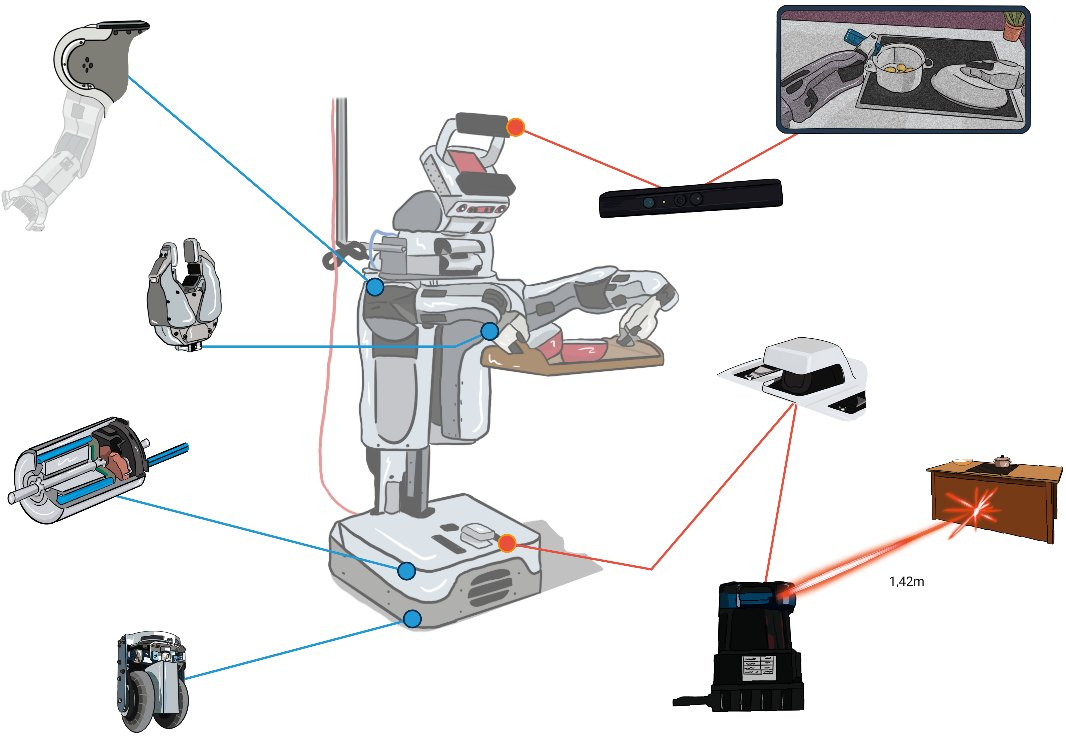

### Questions

Identify the key functional parts of a robot based on the above picture and briefly indicate how they support the execution of function in the above architecture.

---

### Part 3 Answer

#### 1. Key Functional Parts Identification & Architectural Mapping

The diagram decomposes the PR2 robot into two distinct functional feedback loops: the **orange callouts (sensory input & perception)** and the **blue callouts (actuation & kinematic mechanisms)**.

| Diagram Callout | Anatomical Category (from Title) | Functional Classification | Role in Cognitive Architecture (Integration Diagram) |
| :--- | :--- | :--- | :--- |
| **Kinect / RGB-D Sensor & Head Unit** *(Top orange lines)* | **Heads** *(Exteroception vs. Interoception)* | **Sensor** (Vision & 3D Depth) | **`perceive` (Reading $\rightarrow$ Belief):** Emits point clouds and RGB visual streams to ground linguistic referents (e.g., segmenting the target cup on the counter) and localize human pose (Eva). |
| **Planar Laser Scanner / LiDAR** *(Lower orange lines, 1.42 m range)* | **Sensors** *(Exteroception)* | **Sensor** (Time-of-Flight Ranging) | **`perceive` & `know & predict`:** Provides real-time obstacle distance measurements to update local occupancy grids and provide boundary constraints for navigation collision checks in the Semantic Digital Twin. |
| **Two-Finger Parallel Gripper** *(Middle blue line)* | **Grippers vs. Effectors** *(Interoception / Contact)* | **End-Effector** (Grasp Mechanism) | **`act & regulate`:** Directly interfaces with the physical environment, using tactile and torque feedback to regulate grasp normal forces without exceeding safe limits. |
| **Arm Segments & Rotary Joint** *(Upper blue line)* | **Links vs. Joints** *(Proprioception)* | **Kinematic Chain** (7-DOF Arm) | **`know & predict` & `act & regulate`:** Internal optical encoders provide proprioceptive joint configuration ($\theta_t$) feedback; geometric link lengths define reachability and kinematic workspace envelopes simulated in the Twin. |
| **Electric Drive Motor** *(Cutaway motor graphic, lower left)* | **Actuators vs. Sensors** | **Actuator** (Electromechanical Drive) | **`act & regulate`:** Converts commanded joint velocity vectors and trajectory waypoints into physical torque across revolute and prismatic joints. |
| **Dual Caster Wheel Drive Module** *(Bottom blue line)* | **Wheels vs. Legs vs. Bases** | **Mobile Base Locomotion** | **`act & regulate` & `Warrant Gate`:** Executes planar navigation trajectories while enforcing bounded angular and linear accelerations to prevent fluid sloshing during turns. |
| **Telescopic Spine & Central Base** *(Center upright chassis)* | **Torsos vs. Bases** | **Structural Chassis & Elevation** | **`know & predict` (Feasibility):** Actuates vertical torso displacement to adapt the robot's functional height across different workspace elevations (e.g., high kitchen counter vs. low dining table). |


#### 2. Functional Support in the Cognitive Architecture

1. **Perception & State Grounding (`perceive`):**
   - **Exteroceptive Sensors** (Head RGB-D cameras and Base LiDAR) capture external environmental geometry and emit raw `Observation` packets.
   - **Proprioceptive Sensors** (motor optical encoders in the joints) track internal joint angles $\theta_t$, allowing the `PerceptionSystem` to construct an accurate, metric `BeliefState`.

2. **Feasibility Validation & Simulation (`know & predict`):**
   - Physical hardware constraints—such as rigid link lengths, torso elevation range, joint torque boundaries, and motor speed limits—are encoded within the **Semantic Digital Twin**.
   - When System 1 generates a candidate `ParameterPacket`, the Digital Twin verifies reaching feasibility and simulates expected physical side-effects (e.g., contact force, sloshing wave height) against these kinematic limits before the **Warrant Gate** decides to approve execution.

3. **Execution & Closed-Loop Regulation (`act & regulate`):**
   - The **Actuators** (joint motors and wheeled caster base) convert approved parameter packets into continuous real-world motions.
   - **Interoceptive and Tactile Sensors** on the gripper pads provide contact-force feedback loops, allowing the low-level controller to immediately correct micro-slips or abort motion if contact force spikes unexpectedly.